In [24]:
import scanpy as sc
import pandas as pd


In [25]:
old_pd = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855408_232028_matrix.mtx').T

In [26]:
old_pd 

AnnData object with n_obs × n_vars = 9727 × 36601

In [27]:
gene_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855408_232028_features.tsv", header=None)[1]

In [28]:
gene_names

0        MIR1302-2HG
1            FAM138A
2              OR4F5
3         AL627309.1
4         AL627309.3
            ...     
36596     AC141272.1
36597     AC023491.2
36598     AC007325.1
36599     AC007325.4
36600     AC007325.2
Name: 1, Length: 36601, dtype: object

In [29]:
cell_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855408_232028_barcodes.tsv", header=None)[0]

In [30]:
cell_names

0       AAACCCAAGACATATG-1
1       AAACCCAAGCGGACAT-1
2       AAACCCAAGCTACTAC-1
3       AAACCCACACGAAAGC-1
4       AAACCCAGTATTGGCT-1
               ...        
9722    TTTGTTGGTGTTACTG-1
9723    TTTGTTGTCAGCATTG-1
9724    TTTGTTGTCCCTTGTG-1
9725    TTTGTTGTCCGCAAAT-1
9726    TTTGTTGTCGGTCAGC-1
Name: 0, Length: 9727, dtype: object

In [31]:
lineage_barcodes = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855412_232028_lineage_barcodes.csv")
                                                                                                                                                        

In [32]:
lineage_barcodes.set_index("cellbarcode", inplace=True)

In [33]:
lineage_barcodes["lid"].unique().shape

(160,)

In [34]:
old_pd.obs_names = cell_names

In [35]:
old_pd.var_names = gene_names

In [36]:
old_pd.obs["barcode"] = old_pd.obs_names.map(lineage_barcodes["lid"])

In [37]:
adata_no_nan = old_pd[old_pd.obs["barcode"].notna()]

In [38]:

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)


/tmp/ipykernel_2582384/1561050088.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


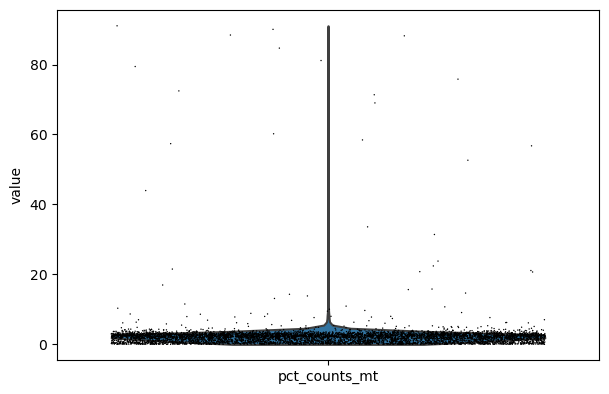

In [39]:
adata_no_nan.var_names_make_unique()
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [40]:

# Filter cells with >3.5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 3.5].copy()


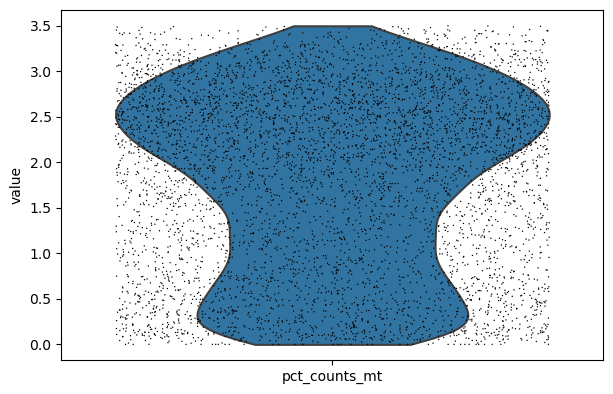

In [41]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [42]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [43]:
# preprocess
sc.pp.normalize_total(adata_no_nan, target_sum=1e4)
#sc.pp.log1p(adata_no_nan)


In [44]:

adata_filtered = adata_no_nan#[:,  adata_no_nan.var.highly_variable]

In [45]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [46]:
df

,MIR1302-2HG,AL627309.1,AL627309.5,AL627309.4,AP006222.2,AL669831.2,LINC01409,FAM87B,LINC01128,LINC00115,...,MT-ND6,MT-CYB,AC011043.1,AC011043.2,AC011841.1,AC240274.1,AC004556.3,AC136352.3,AC007325.4,AC007325.2
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,...,1.878287,24.793388,0.751315,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,...,1.724495,21.728634,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.792121,0.000000,...,1.848282,13.202018,0.000000,0.0,0.0,0.264040,0.000000,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,...,0.837521,20.938023,1.116695,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,...,1.685109,8.425547,0.561703,0.0,0.0,0.561703,0.000000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5690,0.0,0.0,0.0,0.0,0.0,0.0,0.344347,0.0,0.000000,0.172173,...,1.205213,10.158227,0.688693,0.0,0.0,0.516520,0.172173,0.0,0.0,0.0
5691,0.0,0.0,0.0,0.0,0.0,0.0,0.510934,0.0,0.000000,0.000000,...,1.532802,23.502964,0.510934,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0
5692,0.0,0.0,0.0,0.0,0.0,0.0,1.133787,0.0,0.377929,0.000000,...,0.377929,17.384733,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0
5693,0.0,0.0,0.0,0.0,0.0,0.0,0.645161,0.0,0.000000,0.000000,...,1.505376,5.376344,0.860215,0.0,0.0,0.215054,0.000000,0.0,0.0,0.0


In [47]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [48]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [49]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [50]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [51]:
df.drop(columns = ["barcode"], inplace = True)

In [52]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_nolog/knoblich_day16_1_nolog.pkl")


